In [1]:
# ==========================================
# Day 8: Departmental & Activity Transition Matrix
# ==========================================

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Load Scaled Event Log
df_events = pd.read_csv('../data/processed_new/careflow_events_scaled.csv')

# Ensure timestamp sorting
df_events['timestamp'] = pd.to_datetime(df_events['timestamp'])
df_events = df_events.sort_values(by=['case_id', 'timestamp'])

print(f"Loaded Events Shape: {df_events.shape}")
display(df_events.head(3))

Loaded Events Shape: (6964, 27)


,case_id,activity_name,activity_category,timestamp,activity_order,activity_occurrence,is_repeat_activity,minutes_since_prev,minutes_since_case_start,resource,...,day_of_week,split,minutes_since_prev_z,minutes_since_case_start_z,age_z,acuity_z,minutes_since_prev_mm,minutes_since_case_start_mm,age_mm,acuity_mm
0,CF00001,Registration,Administrative,2026-01-06 15:31:00,1,1,False,0.0,0.0,DR06,...,Tuesday,train,-1.209299,-1.257393,0.913392,-0.330091,0.000000,0.000000,0.777778,0.5
1,CF00001,Triage,Administrative,2026-01-06 15:53:00,2,1,False,22.0,22.0,DR06,...,Tuesday,train,0.522505,-0.804665,0.913392,-0.330091,0.366667,0.094017,0.777778,0.5
2,CF00001,Doctor Assessment,Clinical,2026-01-06 16:13:00,3,1,False,20.0,42.0,DR06,...,Tuesday,train,0.365068,-0.393094,0.913392,-0.330091,0.333333,0.179487,0.777778,0.5


In [3]:
# 2. Extract consecutive activity transitions for each patient case
transitions = []
for case_id, group in df_events.groupby('case_id'):
    activities = group['activity_name'].tolist()
    for i in range(len(activities) - 1):
        transitions.append((activities[i], activities[i+1]))

trans_df = pd.DataFrame(transitions, columns=['from_activity', 'to_activity'])

# Create a transition frequency matrix (Crosstab)
transition_matrix = pd.crosstab(trans_df['from_activity'], trans_df['to_activity'])

print("--- Transition Matrix Preview ---")
display(transition_matrix)

--- Transition Matrix Preview ---


to_activity,Discharge,Doctor Assessment,Doctor Reassessment,Documentation Review,Lab Collection,Lab Result,Radiology Result,Triage,X-Ray
from_activity,,,,,,,,,
Doctor Assessment,267,0,0,0,149,0,0,0,584
Doctor Reassessment,146,0,0,0,89,0,0,0,0
Documentation Review,216,0,235,0,133,0,0,0,0
Lab Collection,0,0,0,0,0,371,0,0,0
Lab Result,371,0,0,0,0,0,0,0,0
Radiology Result,0,0,0,349,0,0,0,235,0
Registration,0,0,0,0,0,0,0,1000,0
Triage,0,1000,0,235,0,0,0,0,0
X-Ray,0,0,0,0,0,0,584,0,0


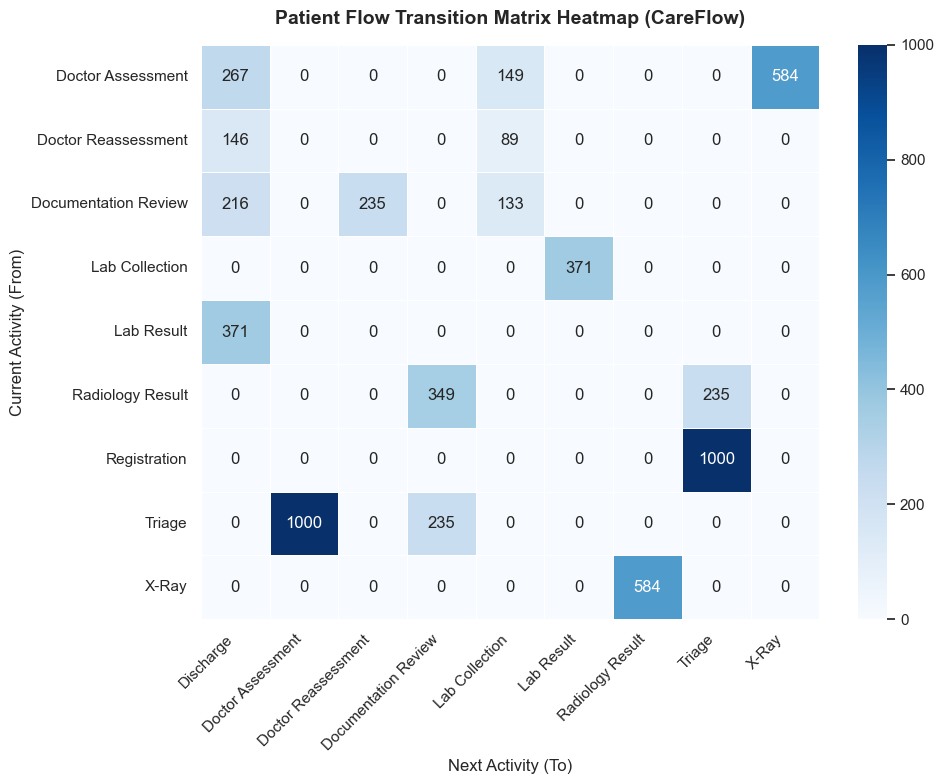

In [4]:
# 3. Visualization: Heatmap of Patient Flow Transitions
plt.figure(figsize=(10, 8))
sns.heatmap(
    transition_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    cbar=True
)

plt.title('Patient Flow Transition Matrix Heatmap (CareFlow)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Next Activity (To)', fontsize=12)
plt.ylabel('Current Activity (From)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 📌 Day 8 Key Insights & Transition Matrix Summary

1. **Pathway Transitions:** The transition matrix maps the exact frequency of patient movement from one clinical stage to the next within the Emergency Department workflow.
2. **Bottleneck Identification:** High-density transition counts highlight standard operational pathways, while alternate branches reveal rework loops or diagnostic diversions (e.g., X-Ray and Lab routing).
3. **Process Flow Validation:** Confirms that patient routing adheres to clinical protocols with expected loopback pathways.